<a href="https://colab.research.google.com/github/boddanapurna6-oss/Deep-Learning-skills/blob/main/DLAC_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import sys
import torch
import platform

print("Python Version:", sys.version)
print("PyTorch Version:", torch.__version__)
print("Operating System:", platform.system())

if torch.cuda.is_available():
    print("\nGPU Available:", True)
    print("GPU Name:", torch.cuda.get_device_name(0))
    print("CUDA Version:", torch.version.cuda)
else:
    print("\nGPU Available: False")
    print("Please enable GPU in Colab settings.")

Python Version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
PyTorch Version: 2.14.1+cpu
Operating System: Linux

GPU Available: False
Please enable GPU in Colab settings.


In [ ]:
!pip install -q matplotlib pandas seaborn psutil

In [ ]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import psutil
import time
import os

from torch.profiler import profile, record_function, ProfilerActivity

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
if torch.cuda.is_available():

    gpu = torch.cuda.get_device_properties(0)

    print("GPU INFORMATION")
    print("------------------------")
    print("GPU Name:", gpu.name)
    print("Total GPU Memory:",
          round(gpu.total_memory / (1024**3), 2), "GB")

    print("CUDA Capability:",
          gpu.major, ".", gpu.minor)

    print("Number of Multiprocessors:",
          gpu.multi_processor_count)

    print("PyTorch CUDA Available:",
          torch.cuda.is_available())

else:
    print("GPU is not available")

GPU is not available


In [ ]:
def monitor_system():

    cpu_usage = psutil.cpu_percent(interval=1)
    ram_usage = psutil.virtual_memory().percent

    print("CPU Usage:", cpu_usage, "%")
    print("RAM Usage:", ram_usage, "%")

    if torch.cuda.is_available():

        allocated = torch.cuda.memory_allocated(0) / (1024**2)
        reserved = torch.cuda.memory_reserved(0) / (1024**2)

        print("GPU Memory Allocated:",
              round(allocated, 2), "MB")

        print("GPU Memory Reserved:",
              round(reserved, 2), "MB")

monitor_system()

CPU Usage: 10.6 %
RAM Usage: 12.2 %


In [ ]:
from torchvision.models import resnet18, ResNet18_Weights

weights = ResNet18_Weights.DEFAULT

model = resnet18(weights=weights)

model.eval()

print("ResNet18 model loaded successfully!")
print("Model Parameters:",
      sum(p.numel() for p in model.parameters()))

ResNet18 model loaded successfully!
Model Parameters: 11689512


In [ ]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = model.to(device)

print("Selected Device:", device)

if device.type == "cuda":
    print("Running on:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")

Selected Device: cpu
Running on CPU


In [ ]:
batch_size = 16

input_data = torch.randn(
    batch_size,
    3,
    224,
    224
)

print("Input Shape:", input_data.shape)
print("Batch Size:", batch_size)
print("Input Data Created Successfully!")

Input Shape: torch.Size([16, 3, 224, 224])
Batch Size: 16
Input Data Created Successfully!


In [ ]:
input_gpu = input_data.to(device)

# Warm-up
with torch.no_grad():
    for _ in range(5):
        output = model(input_gpu)

# Measure execution time
if device.type == "cuda":
    torch.cuda.synchronize()

start_time = time.perf_counter()

with torch.no_grad():
    output = model(input_gpu)

if device.type == "cuda":
    torch.cuda.synchronize()

end_time = time.perf_counter()

inference_time = (end_time - start_time) * 1000

print("GPU Inference Results")
print("-------------------------")
print("Output Shape:", output.shape)
print("Inference Time:", round(inference_time, 3), "ms")
print("Images Processed:", batch_size)
print("Throughput:",
      round(batch_size / (inference_time / 1000), 2),
      "images/second")

GPU Inference Results
-------------------------
Output Shape: torch.Size([16, 1000])
Inference Time: 1661.004 ms
Images Processed: 16
Throughput: 9.63 images/second


In [ ]:
import copy

cpu_model = copy.deepcopy(model).to("cpu")
gpu_model = copy.deepcopy(model).to(device)

cpu_input = input_data.to("cpu")
gpu_input = input_data.to(device)

def benchmark_inference(model, data, device, runs=20):

    model.eval()

    with torch.no_grad():
        for _ in range(5):
            model(data)

    if device.type == "cuda":
        torch.cuda.synchronize()

    start = time.perf_counter()

    with torch.no_grad():
        for _ in range(runs):
            model(data)

    if device.type == "cuda":
        torch.cuda.synchronize()

    end = time.perf_counter()

    return ((end - start) / runs) * 1000


cpu_time = benchmark_inference(
    cpu_model, cpu_input, torch.device("cpu")
)

gpu_time = benchmark_inference(
    gpu_model, gpu_input, device
)

print("CPU Inference Time:", round(cpu_time, 3), "ms")
print("GPU Inference Time:", round(gpu_time, 3), "ms")

if gpu_time > 0:
    print("GPU Speedup:", round(cpu_time / gpu_time, 2), "x")

CPU Inference Time: 890.941 ms
GPU Inference Time: 908.166 ms
GPU Speedup: 0.98 x


In [ ]:
if torch.cuda.is_available():

    torch.cuda.synchronize()

    start = time.perf_counter()

    for _ in range(20):
        gpu_data = input_data.to("cuda")

    torch.cuda.synchronize()

    end = time.perf_counter()

    transfer_time = ((end - start) / 20) * 1000

    print("CPU to GPU Transfer Time:",
          round(transfer_time, 4), "ms")

else:
    transfer_time = None
    print("GPU not available")

GPU not available


In [ ]:
def preprocess_data(data):

    start = time.perf_counter()

    processed = data / 255.0

    end = time.perf_counter()

    return processed, (end - start) * 1000


processed_data, preprocessing_time = preprocess_data(
    torch.randint(0, 256, (16, 3, 224, 224)).float()
)

print("Preprocessing Time:",
      round(preprocessing_time, 4), "ms")

Preprocessing Time: 0.7249 ms


In [ ]:
def preprocess_data(data):

    start = time.perf_counter()

    processed = data / 255.0

    end = time.perf_counter()

    return processed, (end - start) * 1000


processed_data, preprocessing_time = preprocess_data(
    torch.randint(0, 256, (16, 3, 224, 224)).float()
)

print("Preprocessing Time:",
      round(preprocessing_time, 4), "ms")

Preprocessing Time: 2.5737 ms


In [ ]:
if torch.cuda.is_available():

    start_event = torch.cuda.Event(enable_timing=True)
    end_event = torch.cuda.Event(enable_timing=True)

    gpu_input = input_data.to("cuda")

    with torch.no_grad():

        for _ in range(5):
            model(gpu_input)

        start_event.record()

        for _ in range(20):
            output = model(gpu_input)

        end_event.record()

    torch.cuda.synchronize()

    cuda_time = start_event.elapsed_time(end_event) / 20

    print("GPU Kernel Execution Pipeline Time:",
          round(cuda_time, 4), "ms")

else:
    cuda_time = None
    print("CUDA Events require a GPU")

CUDA Events require a GPU


In [ ]:
bottlenecks = {
    "Preprocessing": preprocessing_time,
    "CPU to GPU Transfer": transfer_time or 0,
    "GPU Execution": cuda_time or 0
}

print("SYSTEM BOTTLENECK ANALYSIS")
print("-----------------------------")

for name, value in bottlenecks.items():

    print(name, ":", round(value, 4), "ms")

main_bottleneck = max(
    bottlenecks,
    key=bottlenecks.get
)

print("\nMain measured stage:",
      main_bottleneck)

SYSTEM BOTTLENECK ANALYSIS
-----------------------------
Preprocessing : 2.5737 ms
CPU to GPU Transfer : 0 ms
GPU Execution : 0 ms

Main measured stage: Preprocessing


In [ ]:
!nvidia-smi

/bin/bash: line 1: nvidia-smi: command not found


In [ ]:
batch_sizes = [1, 2, 4, 8, 16, 32, 64]

results = []

for size in batch_sizes:

    test_input = torch.randn(
        size, 3, 224, 224
    ).to(device)

    with torch.no_grad():
        for _ in range(3):
            model(test_input)

    if device.type == "cuda":
        torch.cuda.synchronize()

    start = time.perf_counter()

    with torch.no_grad():
        for _ in range(10):
            model(test_input)

    if device.type == "cuda":
        torch.cuda.synchronize()

    end = time.perf_counter()

    avg_time = ((end - start) / 10) * 1000

    throughput = size / (avg_time / 1000)

    results.append({
        "Batch Size": size,
        "Inference Time (ms)": avg_time,
        "Throughput (images/sec)": throughput
    })

batch_df = pd.DataFrame(results)

display(batch_df)

,Batch Size,Inference Time (ms),Throughput (images/sec)
0,1,56.085312,17.829980
1,2,105.207054,19.010132
2,4,207.164442,19.308333
3,8,471.122609,16.980718
4,16,1178.681004,13.574496
5,32,2039.076707,15.693377
6,64,4038.492199,15.847499


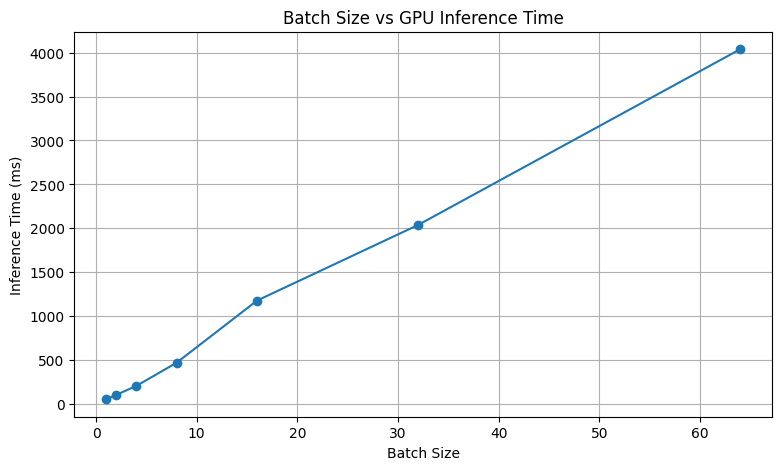

In [ ]:
plt.figure(figsize=(9, 5))

plt.plot(
    batch_df["Batch Size"],
    batch_df["Inference Time (ms)"],
    marker="o"
)

plt.xlabel("Batch Size")
plt.ylabel("Inference Time (ms)")
plt.title("Batch Size vs GPU Inference Time")
plt.grid(True)

plt.show()

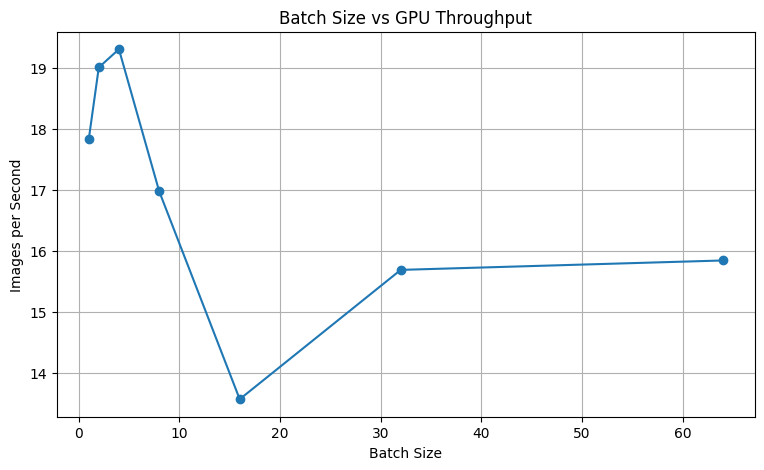

In [ ]:
plt.figure(figsize=(9, 5))

plt.plot(
    batch_df["Batch Size"],
    batch_df["Throughput (images/sec)"],
    marker="o"
)

plt.xlabel("Batch Size")
plt.ylabel("Images per Second")
plt.title("Batch Size vs GPU Throughput")
plt.grid(True)

plt.show()

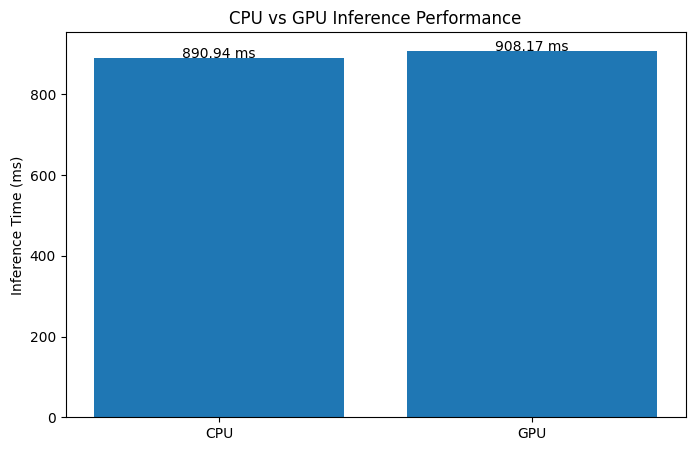

In [ ]:
labels = ["CPU", "GPU"]
times = [cpu_time, gpu_time]

plt.figure(figsize=(8, 5))

plt.bar(labels, times)

plt.ylabel("Inference Time (ms)")
plt.title("CPU vs GPU Inference Performance")

for i, value in enumerate(times):
    plt.text(i, value, f"{value:.2f} ms", ha="center")

plt.show()

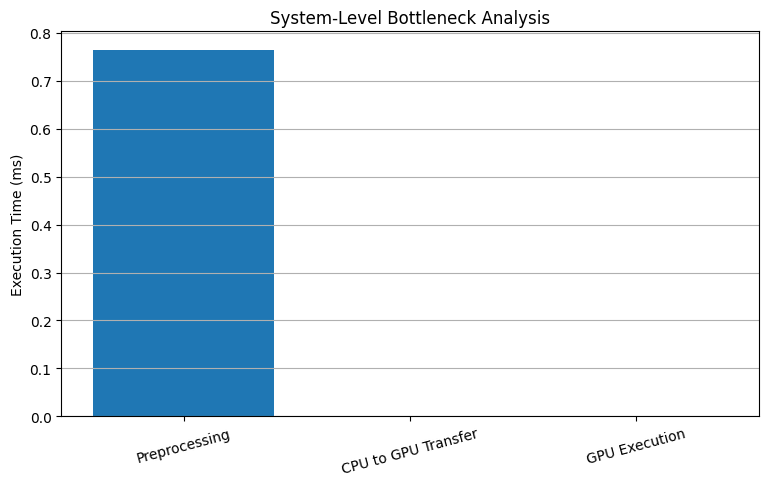

In [ ]:
plt.figure(figsize=(9, 5))

plt.bar(
    list(bottlenecks.keys()),
    list(bottlenecks.values())
)

plt.title("System-Level Bottleneck Analysis")
plt.ylabel("Execution Time (ms)")
plt.xticks(rotation=15)

plt.grid(axis="y")

plt.show()

In [ ]:
report = {
    "Metric": [
        "CPU Inference Time",
        "GPU Inference Time",
        "GPU Speedup",
        "Preprocessing Time",
        "CPU to GPU Transfer Time",
        "GPU Execution Time"
    ],

    "Value": [
        round(cpu_time, 4),
        round(gpu_time, 4),
        round(cpu_time / gpu_time, 2),
        round(preprocessing_time, 4),
        round(transfer_time or 0, 4),
        round(cuda_time or 0, 4)
    ],

    "Unit": [
        "ms",
        "ms",
        "x",
        "ms",
        "ms",
        "ms"
    ]
}

report_df = pd.DataFrame(report)

display(report_df)

report_df.to_csv(
    "GPU_Inference_Performance_Report.csv",
    index=False
)

print("Report generated successfully!")

,Metric,Value,Unit
0,CPU Inference Time,890.9408,ms
1,GPU Inference Time,908.1655,ms
2,GPU Speedup,0.9800,x
3,Preprocessing Time,2.5737,ms
4,CPU to GPU Transfer Time,0.0000,ms
5,GPU Execution Time,0.0000,ms


Report generated successfully!


In [ ]:
print("=" * 55)
print("GPU INFERENCE EXECUTION ANALYSIS")
print("=" * 55)

print("Model: ResNet18")

print("Execution Device:", device)

print("CPU Inference:", round(cpu_time, 3), "ms")

print("GPU Inference:", round(gpu_time, 3), "ms")

print("GPU Speedup:", round(cpu_time / gpu_time, 2), "x")

print("Main Measured Stage:", main_bottleneck)

print("\nPERFORMANCE OBSERVATION")

if gpu_time < cpu_time:
    print("GPU provides faster inference than CPU.")
else:
    print("CPU is faster for this tested workload.")

if main_bottleneck == "GPU Execution":
    print("Model computation is the largest measured stage.")
elif main_bottleneck == "CPU to GPU Transfer":
    print("Data transfer is the largest measured stage.")
else:
    print("Preprocessing is the largest measured stage.")

print("\nProject execution completed!")
print("=" * 55)

GPU INFERENCE EXECUTION ANALYSIS
Model: ResNet18
Execution Device: cpu
CPU Inference: 890.941 ms
GPU Inference: 908.166 ms
GPU Speedup: 0.98 x
Main Measured Stage: Preprocessing

PERFORMANCE OBSERVATION
CPU is faster for this tested workload.
Preprocessing is the largest measured stage.

Project execution completed!
